# DeepConvLSTM on OPPORTUNITY (Google Colab)

Runtime → Change runtime type → **T4 GPU**. Everything (data, trained models, results) is kept in Google Drive under `MyDrive/deepconvlstm`, so it survives when Colab disconnects.

Before the first run, upload `deepconvlstm.zip` to `MyDrive/`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE = '/content/drive/MyDrive/deepconvlstm'
if not os.path.exists(DRIVE):
    !unzip -q /content/drive/MyDrive/deepconvlstm.zip -d /content/drive/MyDrive/
%cd {DRIVE}
!nvidia-smi -L

Mounted at /content/drive
/content/drive/MyDrive/deepconvlstm
GPU 0: Tesla T4 (UUID: GPU-e8d5e521-ab3e-3ace-f374-323eda7abde7)


## 1. Data (only the first time)
Downloads ~300 MB from UCI and writes `data/opportunity.npz` to Drive. Later sessions skip this.

In [ ]:
if not os.path.exists('data/opportunity.npz'):
    !python download_data.py --out /content/raw
    !python preprocess.py --raw /content/raw --out data/opportunity.npz
!ls -lh data

total 124M
-rw------- 1 root root 124M Oct 27 00:41 opportunity.npz


## 2. Train
Each run is saved in `runs/<name>/` on Drive: `best_model.pt` (weights + settings), metrics, confusion matrix, learning curves.

In [ ]:
!python train.py --model deepconvlstm --task gestures --name ref_s0

[ref_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 3,965,778
epoch   1  train_loss 1.0247  val_loss 0.5744  val_F1w 0.8013  val_F1m 0.2516  (39s) *
epoch   2  train_loss 0.5857  val_loss 0.5271  val_F1w 0.8075  val_F1m 0.2569  (76s) *
epoch   3  train_loss 0.4982  val_loss 0.5478  val_F1w 0.8119  val_F1m 0.2672  (114s) *
epoch   4  train_loss 0.4423  val_loss 0.5994  val_F1w 0.8039  val_F1m 0.2946  (151s)
epoch   5  train_loss 0.4113  val_loss 0.4811  val_F1w 0.8477  val_F1m 0.4157  (189s) *
epoch   6  train_loss 0.3800  val_loss 0.4568  val_F1w 0.8550  val_F1m 0.4319  (226s) *
epoch   7  train_loss 0.3592  val_loss 0.4569  val_F1w 0.8495  val_F1m 0.4271  (264s)
epoch   8  train_loss 0.3440  val_loss 0.4888  val_F1w 0.8472  val_F1m 0.4123  (301s)
epoch   9  train_loss 0.3302  val_loss 0.4731  val_F1w 0.8544  val_F1m 0.4552  (339s)
epoch  10  train_loss 0.3174  val_loss 0.5041  val_F1w 0.8636  val_F1m 0.4542  (376s) *
epoch  11  train_lo

In [ ]:
!python train.py --model cnn --task gestures --name ref_s0

[ref_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 7,486,546
epoch   1  train_loss 1.3546  val_loss 0.6949  val_F1w 0.7544  val_F1m 0.0881  (33s) *
epoch   2  train_loss 0.9167  val_loss 0.5942  val_F1w 0.7828  val_F1m 0.1729  (67s) *
epoch   3  train_loss 0.7602  val_loss 0.5780  val_F1w 0.7788  val_F1m 0.1759  (102s)
epoch   4  train_loss 0.6998  val_loss 0.5821  val_F1w 0.7908  val_F1m 0.2180  (137s) *
epoch   5  train_loss 0.6654  val_loss 0.5159  val_F1w 0.8009  val_F1m 0.2465  (171s) *
epoch   6  train_loss 0.6669  val_loss 0.5190  val_F1w 0.8058  val_F1m 0.2620  (206s) *
epoch   7  train_loss 0.6373  val_loss 0.5004  val_F1w 0.8105  val_F1m 0.2872  (241s) *
epoch   8  train_loss 0.6210  val_loss 0.4822  val_F1w 0.8123  val_F1m 0.2960  (275s) *
epoch   9  train_loss 0.6143  val_loss 0.4936  val_F1w 0.8188  val_F1m 0.3195  (309s) *
epoch  10  train_loss 0.6023  val_loss 0.5065  val_F1w 0.8157  val_F1m 0.3155  (344s)
epoch  11  trai

In [ ]:
!python train.py --model deepconvlstm --rnn gru --task gestures --name ref_s0

[ref_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 2,990,418
epoch   1  train_loss 1.0173  val_loss 0.5599  val_F1w 0.8095  val_F1m 0.2815  (34s) *
epoch   2  train_loss 0.5584  val_loss 0.5303  val_F1w 0.8108  val_F1m 0.2716  (68s) *
epoch   3  train_loss 0.4563  val_loss 0.5130  val_F1w 0.8438  val_F1m 0.3884  (104s) *
epoch   4  train_loss 0.3944  val_loss 0.4778  val_F1w 0.8487  val_F1m 0.4210  (140s) *
epoch   5  train_loss 0.3538  val_loss 0.5043  val_F1w 0.8515  val_F1m 0.4317  (177s) *
epoch   6  train_loss 0.3225  val_loss 0.4391  val_F1w 0.8701  val_F1m 0.5019  (214s) *
epoch   7  train_loss 0.2955  val_loss 0.4350  val_F1w 0.8718  val_F1m 0.5435  (251s) *
epoch   8  train_loss 0.2739  val_loss 0.4747  val_F1w 0.8652  val_F1m 0.4920  (287s)
epoch   9  train_loss 0.2536  val_loss 0.4652  val_F1w 0.8733  val_F1m 0.5424  (324s) *
epoch  10  train_loss 0.2380  val_loss 0.4859  val_F1w 0.8809  val_F1m 0.5680  (361s) *
epoch  11  tr

## 3. Reload a saved model for further experiments

In [ ]:
from evaluate import load_trained
import numpy as np, torch
from data import load_split

model, cfg, names = load_trained('runs/ref_s0')
print(cfg['model'], cfg['task'], len(names), 'classes')

test = load_split(np.load('data/opportunity.npz'), 'test', task=cfg['task'], sensors=cfg['sensors'],
                  window=cfg['window'], step=cfg['step'], include_null=not cfg['no_null'])
with torch.no_grad():
    logits = model(test.X[:5].to(next(model.parameters()).device))
print([names[i] for i in logits.argmax(1).tolist()], [names[i] for i in test.y[:5].tolist()])

In [ ]:
!python evaluate.py --run runs/ref_s0 --save-predictions

## 4. Ablations
Run one block per session (see README). Example: block A, 3 seeds.

In [ ]:
!SEEDS='0 1 2' bash ablations.sh A

In [ ]:
!python summarize.py
import pandas as pd
pd.read_csv('results_by_config.csv')

## 5. Workshop 2: Parts 0, D, E, F

This section runs the DEF parts of the workshop on the same setup as above. Sections 2–4 (the tutorial reference runs and the ablation blocks) are **not** run here, so their cells have no output.

Every run is DeepConvLSTM on gestures with Null, 0.8 s windows, RMSProp (lr 1e-3, decay 0.9), batch 100, up to 100 epochs with early stopping (patience 20). Each configuration is trained with seeds 0, 1 and 2, and tables report the mean over seeds (± std where shown); curves, per-class tables and confusion matrices that need a single run use seed 0 unless noted. Each run changes only what its Part says. Finished runs are skipped, so after a disconnect run this section again.


## 2. Code changes for Parts E and F
`train.py` gets three new options. Their defaults reproduce the original behaviour exactly, so runs from Parts 0–C are not affected.

| Option | Part | What it does |
|---|---|---|
| `--warmup N` | E | Linear learning-rate warm-up over the first N epochs, updated every mini-batch: $\eta_t = \eta \cdot \min\left(1, \frac{t+1}{N \cdot B}\right)$, $B$ = mini-batches per epoch |
| `--loss focal` | F | Focal Loss (Lin et al., 2017) instead of cross-entropy: $\mathrm{FL}(p_t) = -(1-p_t)^{\gamma}\,\log p_t$ |
| `--gamma γ` | F | Focusing parameter of the Focal Loss (default 2); γ = 0 gives cross-entropy |

Every run now also saves `batch_loss.csv` (loss and learning rate of every mini-batch) and an `lr` column in `history.csv`. Part E uses them to measure stability.

In [3]:
%%writefile extensions.py
"""Additions to train.py for Workshop 2: Part E (learning-rate warm-up) and Part F (Focal Loss)."""
import torch.nn as nn
import torch.nn.functional as F


class FocalLoss(nn.Module):
    """Multi-class Focal Loss (Lin et al., "Focal Loss for Dense Object Detection", ICCV 2017):

        FL(p_t) = -w_t * (1 - p_t)^gamma * log(p_t)

    p_t is the softmax probability of the true class. Windows the model already gets right
    (p_t -> 1; in OPPORTUNITY mostly Null) are scaled down by (1 - p_t)^gamma, so the gradient
    concentrates on hard, usually rare, gestures. gamma = 0 gives plain cross-entropy.
    `weight` (optional, one value per class) is the alpha_t term of the paper."""

    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma, self.weight = gamma, weight

    def forward(self, logits, target):
        log_pt = F.log_softmax(logits, dim=1).gather(1, target[:, None]).squeeze(1)
        loss = -(1 - log_pt.exp()) ** self.gamma * log_pt
        if self.weight is not None:
            loss = loss * self.weight[target]
        return loss.mean()


def warmup_factor(step, warmup_steps):
    """Linear warm-up: LR multiplier for update `step` (0-based), rising from 1/warmup_steps to 1."""
    return min(1.0, (step + 1) / warmup_steps) if warmup_steps > 0 else 1.0

Overwriting extensions.py


In [4]:
# Apply the changes to train.py (safe to run again: an already patched file is left alone).
import difflib, shutil

PATCHES = [  # (original text, replacement); every original text must occur exactly once
    ("from models import build_model, count_params\n",
     "from models import build_model, count_params\n"
     "from extensions import FocalLoss, warmup_factor\n"),

    ('    g.add_argument("--label-smoothing", type=float, default=0.0)\n',
     '    g.add_argument("--label-smoothing", type=float, default=0.0)\n'
     '    g.add_argument("--loss", choices=["ce", "focal"], default="ce", help="training loss (Part F)")\n'
     '    g.add_argument("--gamma", type=float, default=2.0, help="focal loss focusing parameter")\n'
     '    g.add_argument("--warmup", type=int, default=0, help="linear LR warm-up epochs (Part E)")\n'),

    ("    crit = nn.CrossEntropyLoss(weight=weights, label_smoothing=a.label_smoothing)\n",
     '    if a.loss == "focal":\n'
     "        crit = FocalLoss(gamma=a.gamma, weight=weights)\n"
     "    else:\n"
     "        crit = nn.CrossEntropyLoss(weight=weights, label_smoothing=a.label_smoothing)\n"
     "    warmup_steps = a.warmup * -(-len(ytr) // a.batch_size)  # warm-up epochs x mini-batches per epoch\n"
     "    step, batch_log = 0, []\n"),

    ("            opt.zero_grad()\n"
     "            loss = crit(model(x), y)\n"
     "            loss.backward()\n"
     "            opt.step()\n"
     "            tot += loss.item() * len(y)\n",
     "            if step < warmup_steps:\n"
     "                for pg in opt.param_groups:\n"
     '                    pg["lr"] = a.lr * warmup_factor(step, warmup_steps)\n'
     "            opt.zero_grad()\n"
     "            loss = crit(model(x), y)\n"
     "            loss.backward()\n"
     "            opt.step()\n"
     "            step += 1\n"
     "            batch_loss = loss.item()\n"
     "            tot += batch_loss * len(y)\n"
     '            batch_log.append((epoch, step, opt.param_groups[0]["lr"], batch_loss))\n'),

    ('        hist.append({"epoch": epoch, "train_loss": tot / len(ytr), "val_loss": vloss,\n',
     '        hist.append({"epoch": epoch, "lr": opt.param_groups[0]["lr"], "train_loss": tot / len(ytr),\n'
     '                     "val_loss": vloss,\n'),

    ('    hist.to_csv(os.path.join(out, "history.csv"), index=False)\n',
     '    hist.to_csv(os.path.join(out, "history.csv"), index=False)\n'
     '    pd.DataFrame(batch_log, columns=["epoch", "step", "lr", "loss"]).to_csv(\n'
     '        os.path.join(out, "batch_loss.csv"), index=False)\n'),
]

with open('train.py', 'rb') as f:
    newline = '\r\n' if b'\r\n' in f.read() else '\n'  # keep the file's own line endings
with open('train.py') as f:
    src = f.read()
if 'from extensions import' in src:
    print('train.py is already patched')
else:
    new = src
    for old, rep in PATCHES:
        assert new.count(old) == 1, f'expected exactly one match for:\n{old}'
        new = new.replace(old, rep)
    shutil.copy('train.py', 'train_orig.py')
    with open('train.py', 'w', newline=newline) as f:
        f.write(new)
    print(''.join(difflib.unified_diff(src.splitlines(True), new.splitlines(True), 'train_orig.py', 'train.py')))

train.py is already patched


## 3. Runs
`run(name, options)` trains one configuration for every seed in `SEEDS` and saves it to `runs/<name>_s<seed>/`. Anything not given in `options` is the paper setting. Finished runs are skipped.

In [5]:
SEEDS = [0, 1, 2]  # three seeds per configuration, so differences can be compared with seed-to-seed variation

def run(name, options=''):
    for seed in SEEDS:
        tag = f'{name}_s{seed}'
        if os.path.exists(f'runs/{tag}/metrics.json'):
            print(f'{tag}: already finished, skipped')
            continue
        !python train.py --model deepconvlstm --task gestures --seed {seed} --name {tag} {options}

### Part 0 — reference model
The paper configuration, trained with the patched `train.py` so that it has the same logs (`batch_loss.csv`) as the runs it is compared with.

In [6]:
run('P0_ref')

Training ran outside this notebook, as one SLURM job per run on the Fir cluster (H100 MIG 1g.10gb slice). Each log below is copied unchanged from that job.

===== P0_ref_s0  (SLURM job 786244, logs/dcl_run_P0_ref_786244.out)
$ python train.py --model deepconvlstm --task gestures --seed 0 --name P0_ref_s0
/scratch/daeho/ELEC872/ELEC872 workshop/deepconvlstm/train.py:246: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `t

### Part D — How much regularization is needed?
The reference uses dropout 0.5 only: weight decay is 0 and augmentation is off by default. "No weight decay" and "no augmentation" would therefore be identical to `P0_ref`. Instead we switch all three regularizers on (`D_full`) and remove one at a time (leave-one-out):

| Run | Dropout | Weight decay (L2) | Augmentation |
|---|---|---|---|
| `P0_ref` (paper) | 0.5 | 0 | off |
| `D_full` | 0.5 | 1e-4 | on |
| `D_nodrop` | **0** | 1e-4 | on |
| `D_nowd` | 0.5 | **0** | on |
| `D_noaug` | 0.5 | 1e-4 | **off** |

Dropout acts on the conv features, between the two LSTM layers and before the output layer. Augmentation multiplies every channel by a random gain ~ N(1, 0.1²) and adds Gaussian noise (σ = 0.01) to every training batch (`augment()` in `train.py`).

In [7]:
run('D_full', '--dropout 0.5 --weight-decay 1e-4 --augment')

Training ran outside this notebook, as one SLURM job per run on the Fir cluster (H100 MIG 1g.10gb slice). Each log below is copied unchanged from that job.

===== D_full_s0  (SLURM job 786245, logs/dcl_run_D_full_786245.out)
$ python train.py --model deepconvlstm --task gestures --seed 0 --name D_full_s0 --dropout 0.5 --weight-decay 1e-4 --augment
/scratch/daeho/ELEC872/ELEC872 workshop/deepconvlstm/train.py:246: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they a

In [8]:
run('D_nodrop', '--dropout 0 --weight-decay 1e-4 --augment')

Training ran outside this notebook, as one SLURM job per run on the Fir cluster (H100 MIG 1g.10gb slice). Each log below is copied unchanged from that job.

===== D_nodrop_s0  (SLURM job 786246, logs/dcl_run_D_nodrop_786246.out)
$ python train.py --model deepconvlstm --task gestures --seed 0 --name D_nodrop_s0 --dropout 0 --weight-decay 1e-4 --augment
/scratch/daeho/ELEC872/ELEC872 workshop/deepconvlstm/train.py:246: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless th

In [9]:
run('D_nowd', '--dropout 0.5 --weight-decay 0 --augment')

Training ran outside this notebook, as one SLURM job per run on the Fir cluster (H100 MIG 1g.10gb slice). Each log below is copied unchanged from that job.

===== D_nowd_s0  (SLURM job 786247, logs/dcl_run_D_nowd_786247.out)
$ python train.py --model deepconvlstm --task gestures --seed 0 --name D_nowd_s0 --dropout 0.5 --weight-decay 0 --augment
/scratch/daeho/ELEC872/ELEC872 workshop/deepconvlstm/train.py:246: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are 

In [10]:
run('D_noaug', '--dropout 0.5 --weight-decay 1e-4')

Training ran outside this notebook, as one SLURM job per run on the Fir cluster (H100 MIG 1g.10gb slice). Each log below is copied unchanged from that job.

===== D_noaug_s0  (SLURM job 786248, logs/dcl_run_D_noaug_786248.out)
$ python train.py --model deepconvlstm --task gestures --seed 0 --name D_noaug_s0 --dropout 0.5 --weight-decay 1e-4
/scratch/daeho/ELEC872/ELEC872 workshop/deepconvlstm/train.py:246: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are expl

### Part E — Does a learning-rate warm-up make training more stable?
Same as `P0_ref` (RMSProp, lr 1e-3, batch 100), except that the learning rate rises linearly from almost 0 to 1e-3 over the first 5 epochs (5 × 414 = 2,070 updates) instead of starting at 1e-3. The learning rate itself stays at the paper's 1e-3, so warm-up is the only change.

In [11]:
run('E_warmup5', '--warmup 5')

Training ran outside this notebook, as one SLURM job per run on the Fir cluster (H100 MIG 1g.10gb slice). Each log below is copied unchanged from that job.

===== E_warmup5_s0  (SLURM job 786249, logs/dcl_run_E_warmup5_786249.out)
$ python train.py --model deepconvlstm --task gestures --seed 0 --name E_warmup5_s0 --warmup 5
/scratch/daeho/ELEC872/ELEC872 workshop/deepconvlstm/train.py:246: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowliste

### Part F — Does handling class imbalance help rare gestures?
Same as `P0_ref` with cross-entropy replaced by Focal Loss, γ = 2 (the value Lin et al. found best). No class weights (α), so only the shape of the loss changes. The best epoch is still chosen on validation weighted F1, as in every other run. Note that the printed `train_loss` of this run is the focal loss, while `val_loss` is always cross-entropy, so the two are not comparable here.

In [12]:
run('F_focal', '--loss focal --gamma 2')

Training ran outside this notebook, as one SLURM job per run on the Fir cluster (H100 MIG 1g.10gb slice). Each log below is copied unchanged from that job.

===== F_focal_s0  (SLURM job 786250, logs/dcl_run_F_focal_786250.out)
$ python train.py --model deepconvlstm --task gestures --seed 0 --name F_focal_s0 --loss focal --gamma 2
/scratch/daeho/ELEC872/ELEC872 workshop/deepconvlstm/train.py:246: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allo

## 4. Results
Loads every finished run. For over-fitting (Part D) each saved model is also scored on the **training** windows in eval mode (no dropout, no augmentation); this is cached in `train_eval.json`. Figures are saved to `figures/` for the report.

In [13]:
import glob, json, warnings
warnings.filterwarnings('ignore', category=FutureWarning)  # torch.load notice, not relevant here
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from data import load_split
from evaluate import load_trained
from train import predict, scores

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e3', 'axes.axisbelow': True, 'axes.titlelocation': 'left',
                     'lines.linewidth': 2, 'legend.frameon': False})
COLORS = {'P0_ref': '#2a78d6', 'D_full': '#eb6834', 'D_nodrop': '#1baf7a', 'D_nowd': '#eda100',
          'D_noaug': '#e87ba4', 'E_warmup5': '#008300', 'F_focal': '#e34948'}  # one fixed colour per run
os.makedirs('figures', exist_ok=True)
npz = np.load('data/opportunity.npz')


def train_eval(run_dir):
    """Scores of the saved model on the training windows in eval mode (cached in train_eval.json)."""
    path = os.path.join(run_dir, 'train_eval.json')
    if not os.path.exists(path):
        model, cfg, _ = load_trained(run_dir)
        ds = load_split(npz, 'train', task=cfg['task'], sensors=cfg['sensors'], window=cfg['window'],
                        step=cfg['step'], include_null=not cfg['no_null'])
        dev = next(model.parameters()).device
        y, p, loss = predict(model, ds.X.to(dev), ds.y.to(dev))
        with open(path, 'w') as f:
            json.dump({**scores(y, p), 'loss': loss}, f)
    with open(path) as f:
        return json.load(f)


def per_class(run_dir):
    """Per-class test precision, recall, F1 and support, from the saved confusion matrix."""
    cm = pd.read_csv(os.path.join(run_dir, 'confusion_matrix.csv'), index_col=0)
    tp, pred, true = np.diag(cm.values), cm.values.sum(0), cm.values.sum(1)
    prec, rec = tp / np.maximum(pred, 1), tp / np.maximum(true, 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    return pd.DataFrame({'precision': prec, 'recall': rec, 'F1': f1, 'support': true}, index=cm.index)


R = {}  # run name -> one dict per finished seed
for name in COLORS:
    for f in sorted(glob.glob(f'runs/{name}_s*/metrics.json')):
        d = os.path.dirname(f)
        with open(f) as fh:
            m = json.load(fh)
        R.setdefault(name, []).append({'dir': d, 'm': m, 'hist': pd.read_csv(os.path.join(d, 'history.csv')),
                                       'batch': pd.read_csv(os.path.join(d, 'batch_loss.csv')),
                                       'train': train_eval(d)})
print('finished:', {k: len(v) for k, v in R.items()})
print('missing: ', [k for k in COLORS if k not in R] or 'none')


def summary(names):
    """Test scores and over-fitting gap per run: mean over seeds, plus std when there are several seeds."""
    rows = [{'run': n, 'test F1w': r['m']['test_f1_weighted'], 'test F1m': r['m']['test_f1_macro'],
             'test acc': r['m']['test_accuracy'], 'train F1m': r['train']['f1_macro'],
             'gap F1m (train-test)': r['train']['f1_macro'] - r['m']['test_f1_macro'],
             'best epoch': r['m']['best_epoch'], 'epochs': len(r['hist'])}
            for n in names for r in R.get(n, [])]
    if not rows:
        return 'no finished runs'
    g = pd.DataFrame(rows).groupby('run', sort=False)
    out = g.mean()
    if g.size().max() > 1:
        out = out.join(g[['test F1w', 'test F1m']].std().add_suffix(' std'))
    return out.round(4)

finished: {'P0_ref': 3, 'D_full': 3, 'D_nodrop': 3, 'D_nowd': 3, 'D_noaug': 3, 'E_warmup5': 3, 'F_focal': 3}
missing:  none


### Part D results
The paper's claim ("no difference") holds for a regularizer if removing it leaves test F1 unchanged. Over-fitting shows up as a larger gap between macro F1 on the training windows and on the test windows. The training loss of runs with dropout or augmentation is measured with them switched on, so compare it only between runs with the same regularizers.

,test F1w,test F1m,test acc,train F1m,gap F1m (train-test),best epoch,epochs,test F1w std,test F1m std
run,,,,,,,,,
P0_ref,0.8912,0.5802,0.8935,0.9019,0.3217,34.6667,54.6667,0.0039,0.0288
D_full,0.8825,0.5621,0.8826,0.8773,0.3152,45.6667,65.6667,0.0074,0.0119
D_nodrop,0.8848,0.5688,0.8886,0.9401,0.3714,42.3333,62.3333,0.0036,0.0127
D_nowd,0.8808,0.5532,0.8831,0.8516,0.2984,36.0000,56.0000,0.0047,0.0409
D_noaug,0.8900,0.5777,0.8917,0.9190,0.3414,51.0000,71.0000,0.0056,0.0156


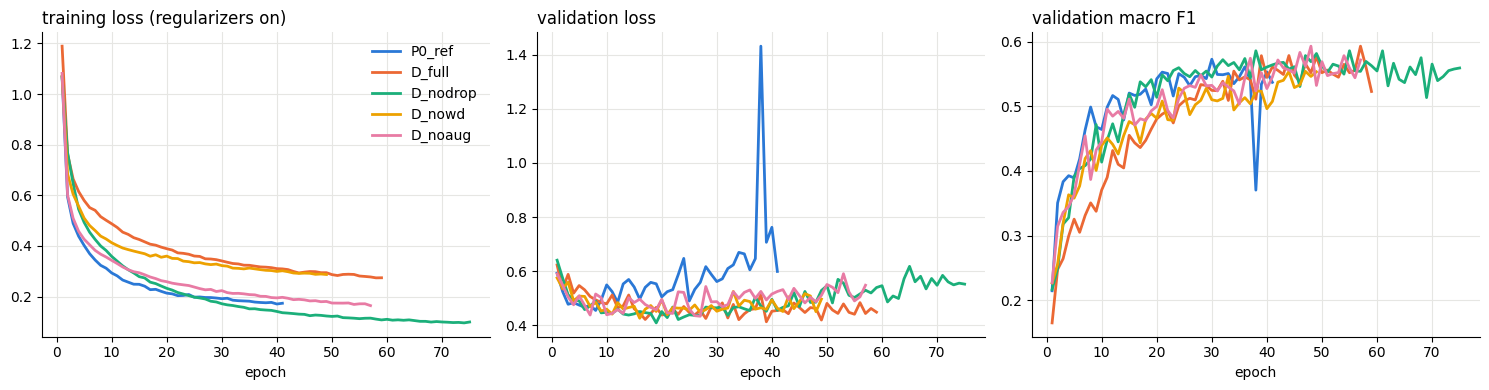

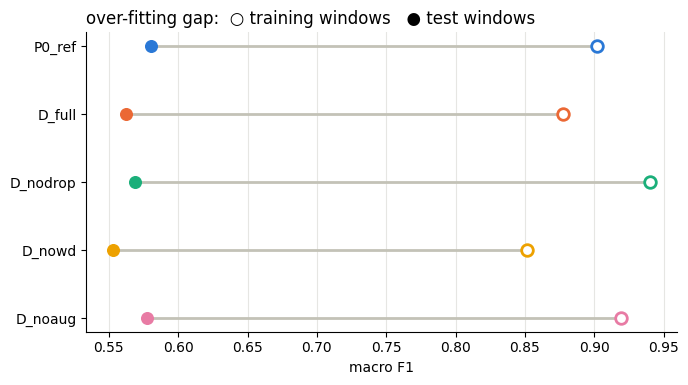

In [14]:
D = [n for n in ['P0_ref', 'D_full', 'D_nodrop', 'D_nowd', 'D_noaug'] if n in R]
s = summary(D)
display(s)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for n in D:
    h = R[n][0]['hist']
    for a, col in zip(ax, ['train_loss', 'val_loss', 'val_f1_macro']):
        a.plot(h.epoch, h[col], color=COLORS[n], label=n)
for a, t in zip(ax, ['training loss (regularizers on)', 'validation loss', 'validation macro F1']):
    a.set_title(t); a.set_xlabel('epoch')
ax[0].legend()
fig.tight_layout(); fig.savefig('figures/partD_curves.png', dpi=150); plt.show()

fig, a = plt.subplots(figsize=(7, 0.55 * len(D) + 1.2))
for i, n in enumerate(D):
    a.plot([s.loc[n, 'test F1m'], s.loc[n, 'train F1m']], [i, i], color='#c3c2b7', zorder=1)
    a.scatter(s.loc[n, 'train F1m'], i, s=70, facecolors='white', edgecolors=COLORS[n], linewidths=2, zorder=2)
    a.scatter(s.loc[n, 'test F1m'], i, s=70, color=COLORS[n], zorder=2)
a.set_yticks(range(len(D)), D); a.invert_yaxis(); a.grid(axis='y', visible=False)
a.set_xlabel('macro F1'); a.set_title('over-fitting gap:  ○ training windows   ● test windows')
fig.tight_layout(); fig.savefig('figures/partD_gap.png', dpi=150); plt.show()

### Part E results
Warm-up only acts in epochs 1–5, so look first at the top row of the figure and the first epochs of the bottom row. Stability measures (lower = more stable):
- **batch-loss jitter, ep 1–5**: std of each mini-batch loss relative to its 50-batch running mean;
- **val-loss rises, ep 1–15**: epochs in which validation loss went up instead of down;
- **largest val F1w drop**: biggest fall of validation weighted F1 from one epoch to the next;
- **share of epochs train loss rose**: over the whole run.

The table is the mean over seeds; the figure shows seed 0.

,"batch-loss jitter, ep 1-5","val-loss rises, ep 1-15",largest val F1w drop,share of epochs train loss rose,best epoch,test F1w,test F1m
P0_ref,0.2086,6.0000,0.0319,0.2572,34.6667,0.8912,0.5802
E_warmup5,0.1884,6.6667,0.0210,0.2327,56.3333,0.8935,0.6035


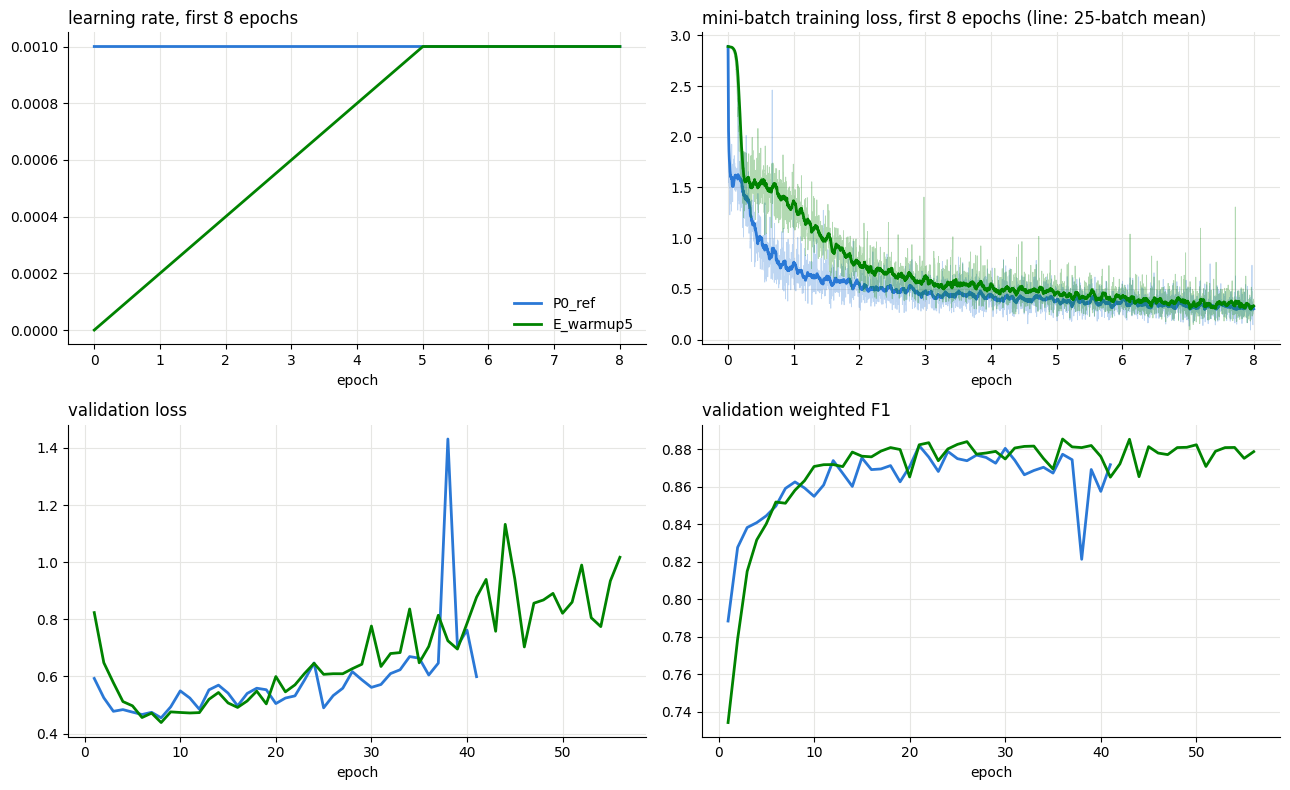

In [15]:
E = [n for n in ['P0_ref', 'E_warmup5'] if n in R]

def stability(r):
    b, h = r['batch'], r['hist']
    early = b.loss[b.epoch <= 5]
    return {'batch-loss jitter, ep 1-5': (early / early.rolling(50, center=True, min_periods=1).mean() - 1).std(),
            'val-loss rises, ep 1-15': int((h.val_loss[:15].diff() > 0).sum()),
            'largest val F1w drop': (-h.val_f1_weighted.diff()).max(),
            'share of epochs train loss rose': (h.train_loss.diff().iloc[1:] > 0).mean(),
            'best epoch': r['m']['best_epoch'],
            'test F1w': r['m']['test_f1_weighted'], 'test F1m': r['m']['test_f1_macro']}

display(pd.DataFrame({n: pd.DataFrame([stability(r) for r in R[n]]).mean() for n in E}).T.round(4))

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for n in E:
    b, h = R[n][0]['batch'], R[n][0]['hist']
    x = b.step / (b.epoch == 1).sum()  # mini-batch position in epochs
    first = x <= 8
    ax[0, 0].plot(x[first], b.lr[first], color=COLORS[n], label=n)
    ax[0, 1].plot(x[first], b.loss[first], color=COLORS[n], lw=0.6, alpha=0.3)
    ax[0, 1].plot(x[first], b.loss.rolling(25, min_periods=1).mean()[first], color=COLORS[n], label=n)
    ax[1, 0].plot(h.epoch, h.val_loss, color=COLORS[n], label=n)
    ax[1, 1].plot(h.epoch, h.val_f1_weighted, color=COLORS[n], label=n)
titles = ['learning rate, first 8 epochs', 'mini-batch training loss, first 8 epochs (line: 25-batch mean)',
          'validation loss', 'validation weighted F1']
for a, t in zip(ax.flat, titles):
    a.set_title(t); a.set_xlabel('epoch')
ax[0, 0].legend()
fig.tight_layout(); fig.savefig('figures/partE_stability.png', dpi=150); plt.show()

### Part F results
The paper reports only weighted F1, which Null (83% of the test windows) dominates. Macro F1, macro F1 over the 17 gestures alone, and the per-class F1 of the rare gestures show whether Focal Loss helps them. Scores are the mean over seeds; the confusion matrices are seed 0. A lower Null precision means the model now predicts gestures more often, including some false alarms.

,test F1w,test F1m,"F1m, 17 gestures",Null precision,Null recall
paper (DeepConvLSTM),0.9150,NaN,NaN,NaN,NaN
P0_ref,0.8912,0.5802,0.5584,0.9418,0.9578
F_focal,0.8922,0.5886,0.5675,0.9471,0.9488


,test windows,F1 P0_ref,F1 F_focal,change
Close Drawer 2,27.0,0.353,0.313,-0.040
Open Drawer 1,39.0,0.406,0.368,-0.038
Open Drawer 2,40.0,0.324,0.392,0.068
Close Drawer 1,42.0,0.355,0.422,0.067
Open Door 1,58.0,0.633,0.605,-0.028
Close Door 1,60.0,0.649,0.623,-0.026
Close Drawer 3,60.0,0.486,0.535,0.049
Open Drawer 3,65.0,0.594,0.574,-0.019
Close Dishwasher,78.0,0.458,0.442,-0.017
Close Door 2,82.0,0.843,0.825,-0.017


9 of 17 gestures improve; mean change on the 12 gestures with fewer than 100 test windows: -0.000


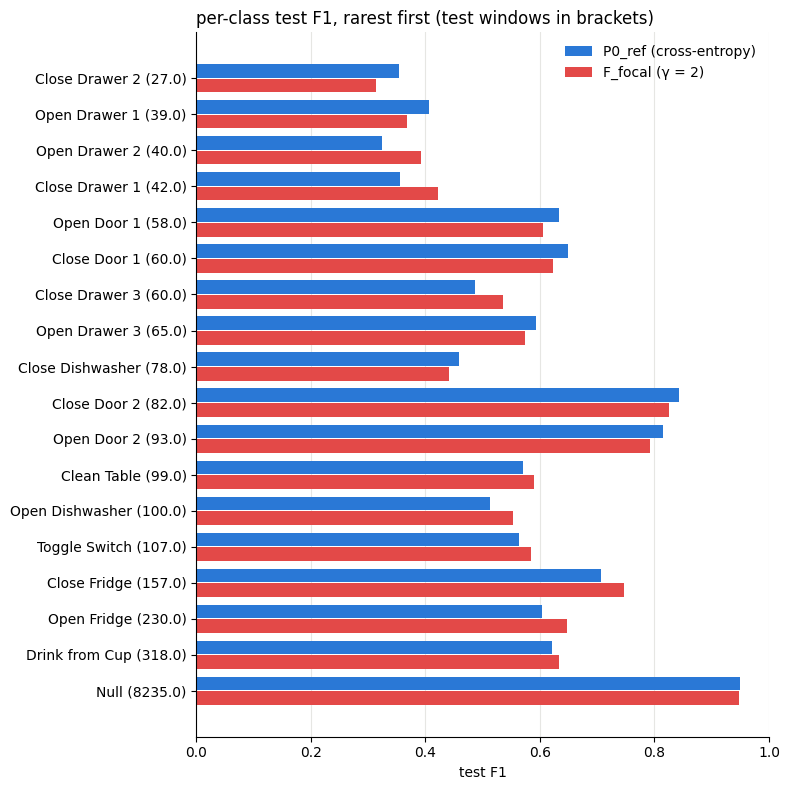

P0_ref


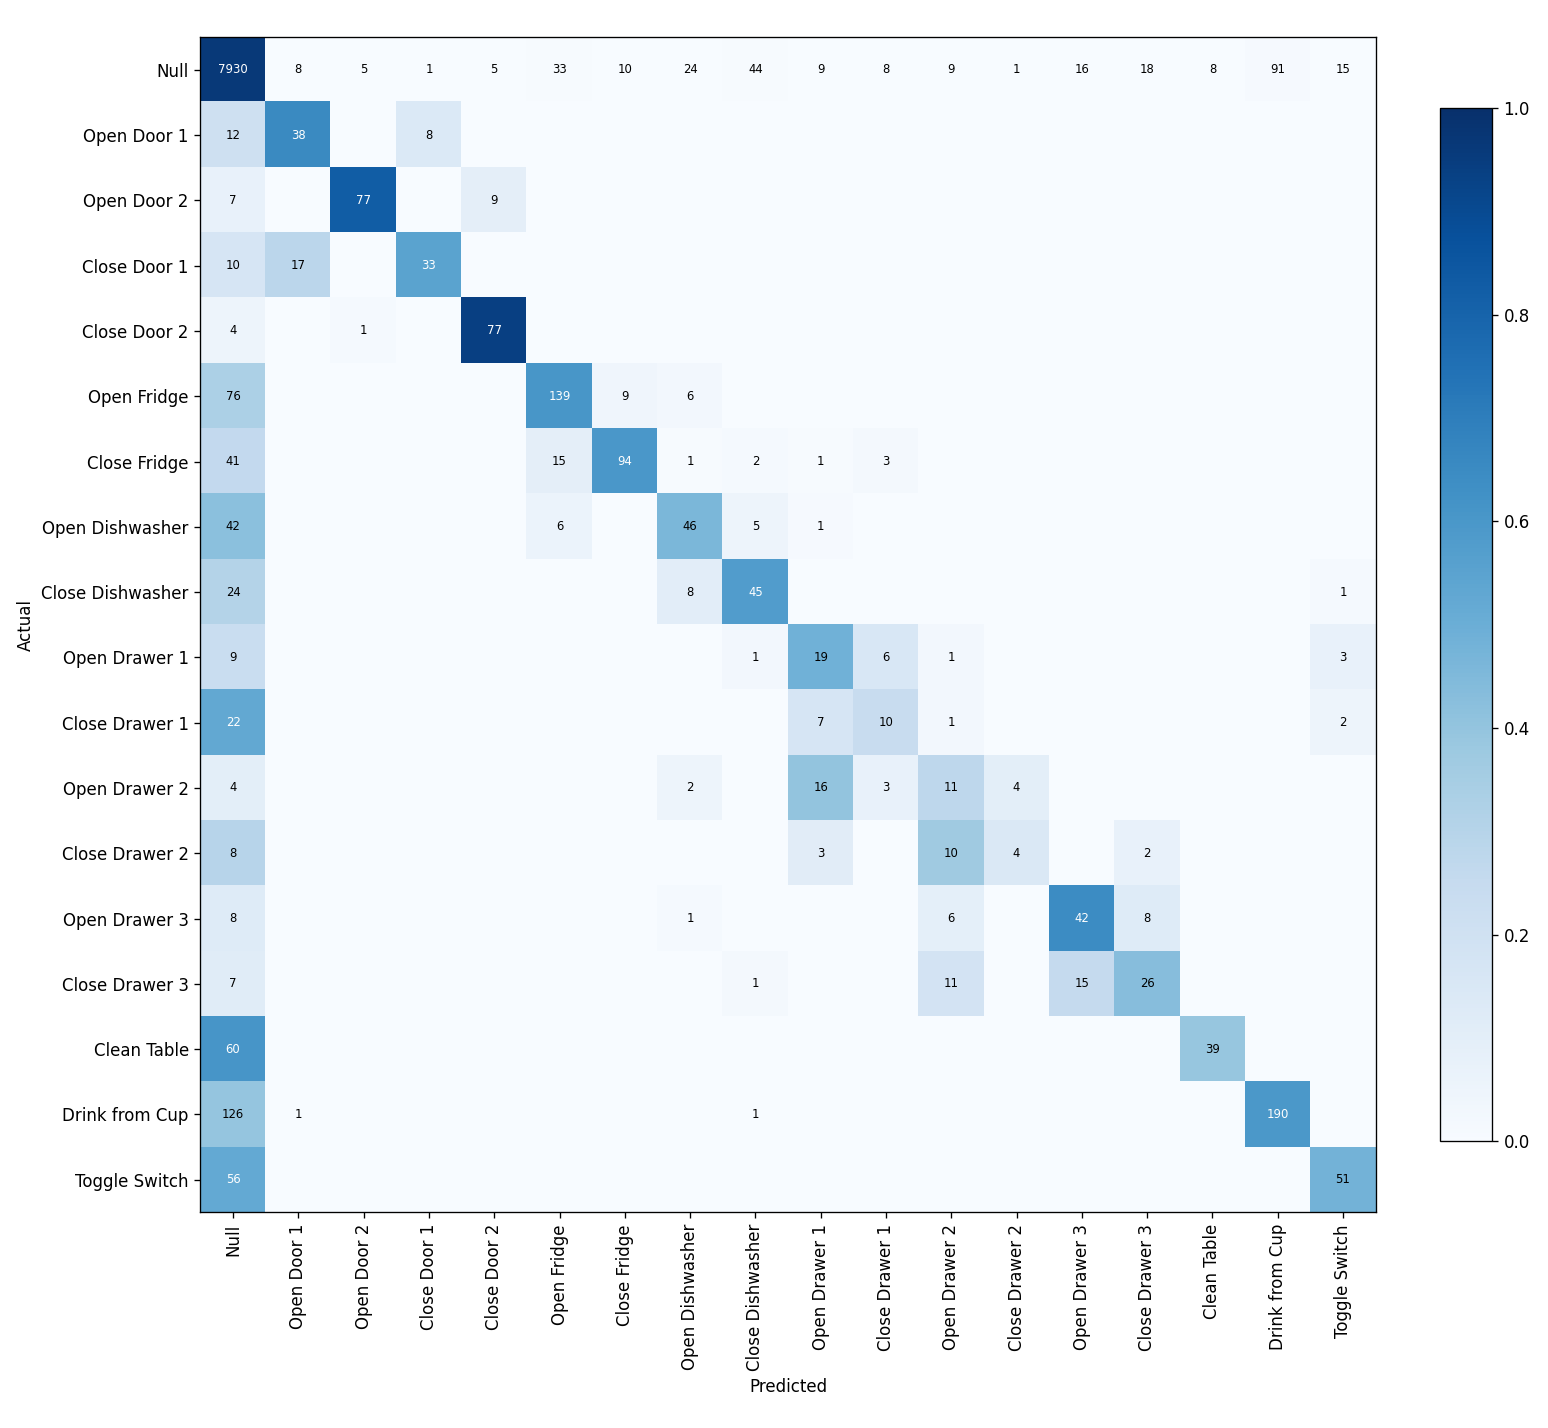

F_focal


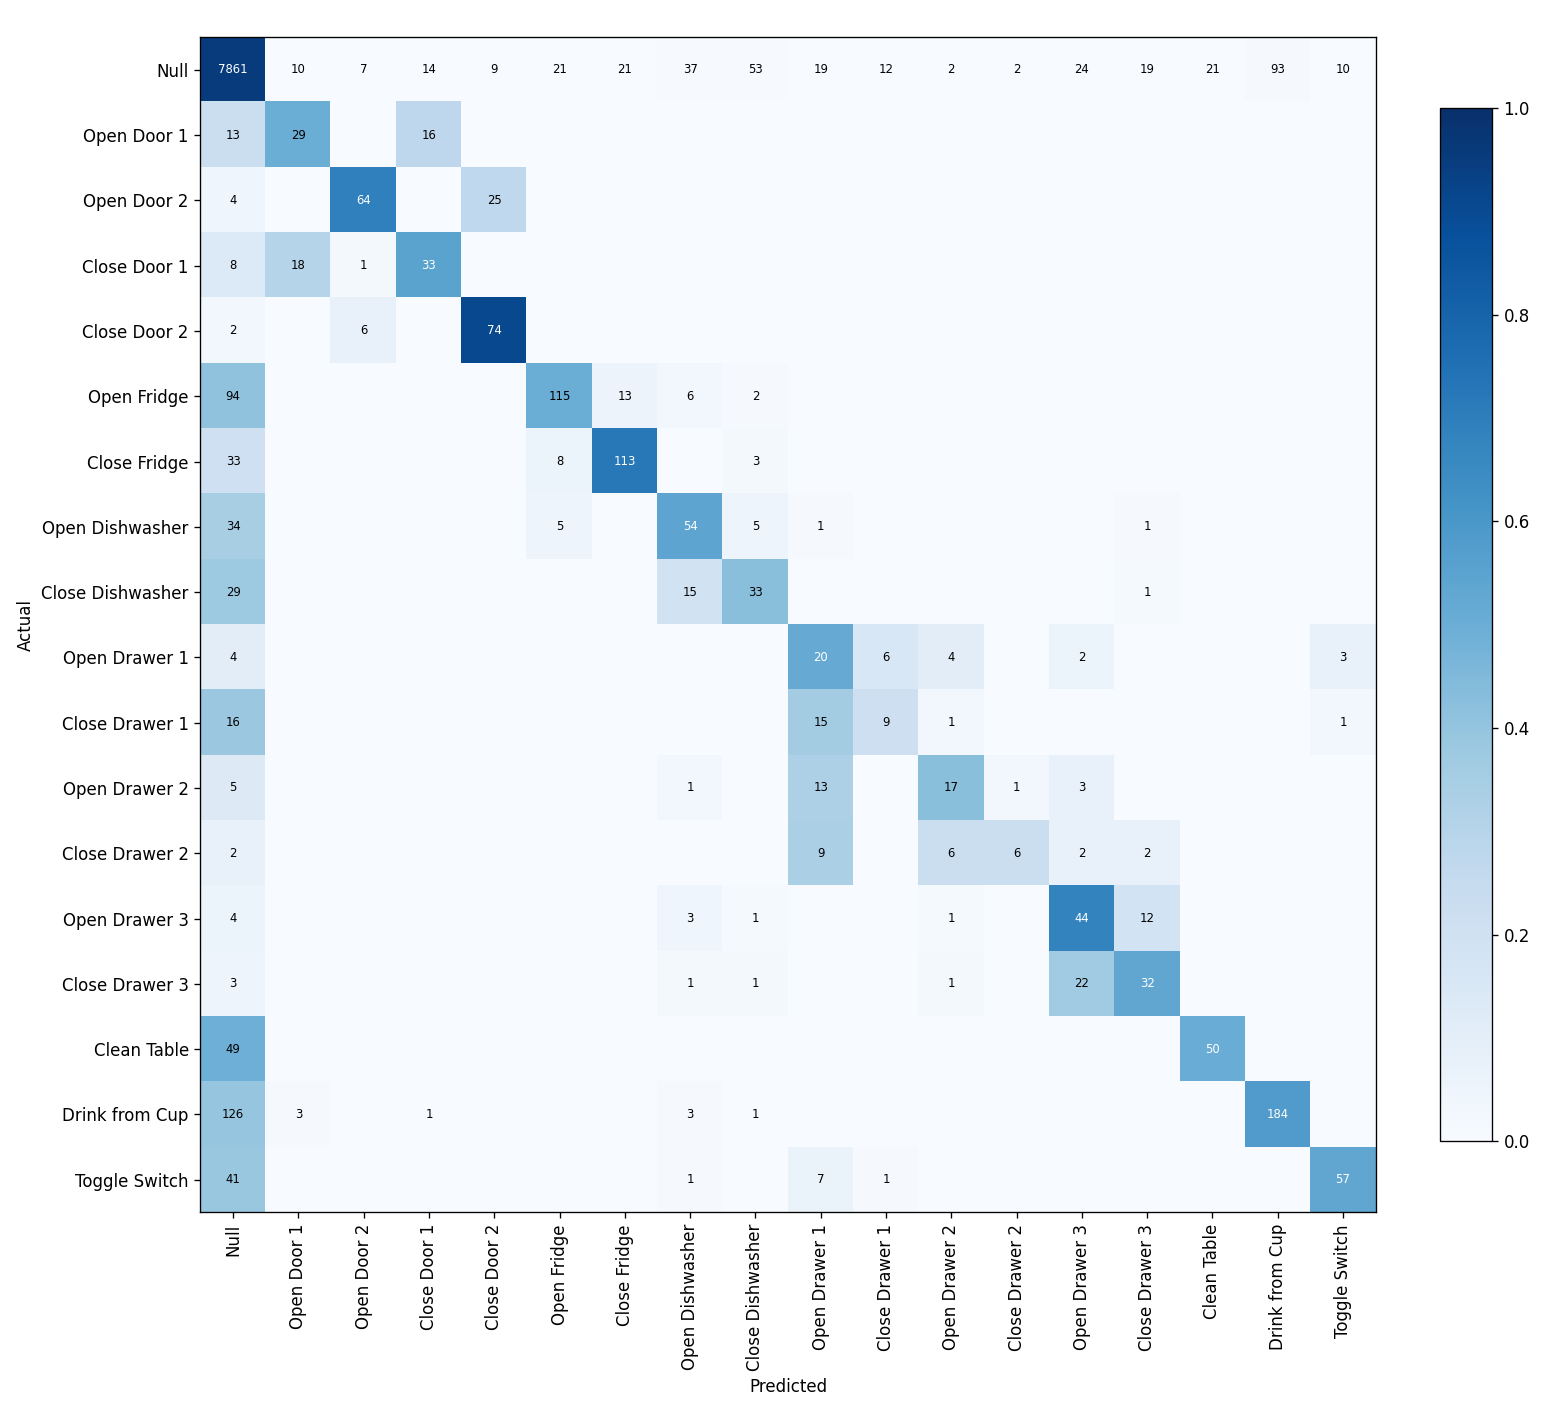

In [16]:
FR = [n for n in ['P0_ref', 'F_focal'] if n in R]
pc = {n: pd.concat([per_class(r['dir']) for r in R[n]]).groupby(level=0, sort=False).mean() for n in FR}  # mean over seeds

PAPER_F1W = 0.915  # Ordóñez & Roggen (2016), Table 4: DeepConvLSTM, gestures with Null (weighted F1 only)
rows = {'paper (DeepConvLSTM)': {'test F1w': PAPER_F1W}}
for n in FR:
    m = pd.DataFrame([r['m'] for r in R[n]])[['test_f1_weighted', 'test_f1_macro']].mean()
    rows[n] = {'test F1w': m['test_f1_weighted'], 'test F1m': m['test_f1_macro'],
               'F1m, 17 gestures': pc[n].F1.drop('Null').mean(),
               'Null precision': pc[n].precision['Null'], 'Null recall': pc[n].recall['Null']}
display(pd.DataFrame(rows).T.round(4))

if len(FR) == 2:
    d = pd.DataFrame({'test windows': pc['P0_ref'].support, 'F1 P0_ref': pc['P0_ref'].F1,
                      'F1 F_focal': pc['F_focal'].F1}).sort_values('test windows')
    d['change'] = d['F1 F_focal'] - d['F1 P0_ref']
    display(d.round(3))
    g = d.drop('Null')
    rare = g[g['test windows'] < 100]
    print(f"{(g['change'] > 0).sum()} of {len(g)} gestures improve; mean change on the {len(rare)} gestures "
          f"with fewer than 100 test windows: {rare['change'].mean():+.3f}")

    fig, a = plt.subplots(figsize=(8, 8))
    yy = np.arange(len(d))
    a.barh(yy - 0.2, d['F1 P0_ref'], height=0.38, color=COLORS['P0_ref'], label='P0_ref (cross-entropy)')
    a.barh(yy + 0.2, d['F1 F_focal'], height=0.38, color=COLORS['F_focal'], label='F_focal (γ = 2)')
    a.set_yticks(yy, [f'{c} ({k})' for c, k in zip(d.index, d['test windows'])])
    a.invert_yaxis(); a.grid(axis='y', visible=False); a.set_xlim(0, 1)
    a.set_xlabel('test F1'); a.set_title('per-class test F1, rarest first (test windows in brackets)')
    a.legend(loc='upper right')
    fig.tight_layout(); fig.savefig('figures/partF_per_class.png', dpi=150); plt.show()

for n in FR:
    print(n); display(Image(os.path.join(R[n][0]['dir'], 'confusion_matrix.png'), width=650))

## 5. All runs (Parts 0–F)

In [17]:
!python summarize.py
pd.read_csv('results_by_config.csv')

         run    config        model     task  null sensors  window  n_conv  params  best_epoch  train_min  test_F1_weighted  test_F1_macro  test_acc
   D_full_s0    D_full deepconvlstm gestures  True     all      24       4 3965778          39        8.3            0.8797         0.5648    0.8797
   D_full_s1    D_full deepconvlstm gestures  True     all      24       4 3965778          39        9.0            0.8769         0.5491    0.8752
   D_full_s2    D_full deepconvlstm gestures  True     all      24       4 3965778          59       10.9            0.8910         0.5725    0.8930
  D_noaug_s0   D_noaug deepconvlstm gestures  True     all      24       4 3965778          37        8.0            0.8959         0.5745    0.8980
  D_noaug_s1   D_noaug deepconvlstm gestures  True     all      24       4 3965778          75       13.2            0.8895         0.5946    0.8920
  D_noaug_s2   D_noaug deepconvlstm gestures  True     all      24       4 3965778          41        8.2 


Mean over seeds:
           n   params  F1w_mean  F1w_std  F1m_mean  F1m_std  train_min
config                                                                
D_full     3  3965778    0.8825   0.0074    0.5621   0.0119     9.4000
D_noaug    3  3965778    0.8900   0.0056    0.5777   0.0156     9.8000
D_nodrop   3  3965778    0.8848   0.0036    0.5688   0.0127     8.2000
D_nowd     3  3965778    0.8808   0.0047    0.5532   0.0409     7.8333
E_warmup5  3  3965778    0.8935   0.0036    0.6035   0.0156    10.4000
F_focal    3  3965778    0.8922   0.0035    0.5886   0.0289     8.4667
P0_ref     3  3965778    0.8912   0.0039    0.5802   0.0288     8.2000


,config,n,params,F1w_mean,F1w_std,F1m_mean,F1m_std,train_min
0,D_full,3,3965778,0.8825,0.0074,0.5621,0.0119,9.4000
1,D_noaug,3,3965778,0.8900,0.0056,0.5777,0.0156,9.8000
2,D_nodrop,3,3965778,0.8848,0.0036,0.5688,0.0127,8.2000
3,D_nowd,3,3965778,0.8808,0.0047,0.5532,0.0409,7.8333
4,E_warmup5,3,3965778,0.8935,0.0036,0.6035,0.0156,10.4000
5,F_focal,3,3965778,0.8922,0.0035,0.5886,0.0289,8.4667
6,P0_ref,3,3965778,0.8912,0.0039,0.5802,0.0288,8.2000
